In [6]:
%matplotlib widget

def plot_la_interactive(t, sigs, names, unit="ns", snap=True, title=""):
    scale = {"s": 1.0, "ms": 1e-3, "us": 1e-6, "ns": 1e-9}[unit]   # unit -> seconds
    n_ch = len(sigs)
    fig, axes = plt.subplots(n_ch, 1, figsize=(11, 1 + 0.7 * n_ch),
                             sharex=True, squeeze=False)
    axs = axes[:, 0]

    edge_times = []
    for ax, name, sig in zip(axs, names, sigs):
        sig = np.asarray(sig)
        ax.step(t, sig, where="post")
        ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=8)
        ax.set_yticks([0, 1])
        ax.set_ylim(-0.2, 1.2)
        ax.grid(True, alpha=0.3)
        edge_times.append(t[np.flatnonzero(np.diff(sig) != 0) + 1])
    edges = np.sort(np.concatenate(edge_times))

    axs[-1].set_xlabel(f"time ({unit})")
    help_txt = "Left-click: cursor A/B | Right-click: clear"
    fig.suptitle(f"{title}\n{help_txt}" if title else help_txt, fontsize=9)

    marks, lines = [], []

    def clear():
        for ln in lines:
            ln.remove()
        lines.clear()
        marks.clear()

    def on_click(event):
        tb = fig.canvas.toolbar
        if tb is not None and getattr(tb, "mode", "") != "":
            return                      # zoom/pan tool active
        if event.inaxes not in axs:
            return
        if event.button == 3:
            clear()
            fig.suptitle(f"{title}\n{help_txt}" if title else help_txt, fontsize=9)
            fig.canvas.draw_idle()
            return
        if event.button != 1:
            return

        x = event.xdata
        if snap and edges.size:
            x = edges[np.argmin(np.abs(edges - x))]
        if len(marks) == 2:
            clear()
        marks.append(x)
        color = "tab:red" if len(marks) == 1 else "tab:green"
        for ax in axs:
            lines.append(ax.axvline(x, color=color, linestyle="--", lw=1))

        if len(marks) == 1:
            msg = f"A = {x:.2f} {unit}"
        else:
            dt = abs(marks[1] - marks[0])
            f = 1 / (dt * scale) if dt > 0 else float("nan")
            msg = (f"A = {marks[0]:.2f} {unit}   B = {marks[1]:.2f} {unit}   "
                   f"Δt = {dt:.2f} {unit}   1/Δt = {f/1e6:.3f} MHz")
        fig.suptitle(msg, fontsize=10)
        fig.canvas.draw_idle()

    fig.canvas.mpl_connect("button_press_event", on_click)
    fig.tight_layout()
    plt.show()
    return fig


def pick_time_unit(span_s):
    """Return (unit_name, factor) so that span_s * factor is a readable number."""
    for name, factor in (("s", 1.0), ("ms", 1e3), ("us", 1e6), ("ns", 1e9)):
        if span_s * factor >= 1:        # span is at least 1 of this unit
            return name, factor
    return "ps", 1e12

def calc_la_time_axis_in_s(scope, sigs):
    # the time axis in seconds, from the real LA sample rate
    f_la = scope.LA.sampling_clock_frequency / scope.LA.downsample
    n = len(sigs[0])
    t_s = np.arange(n) / f_la
    return t_s, n

def calc_la_unit(scope, sigs):
    t_s, n = calc_la_time_axis_in_s(scope, sigs)
    unit, factor = pick_time_unit(t_s[-1])   # based on the total capture length
    t = t_s * factor
    print(f"{n} samples, span = {t[-1]:.2f} {unit}, sample period = {1/f_la*factor:.2f} {unit}")
    return unit

LA_NAMES = {
    "glitch": [
        "glitch output",
        "glitch src clock",
        "MMCM1 (offset) out",
        "MMCM2 (width) out",
        "glitch go",
        "capture trigger",
        "glitch enable",
        "manual trig (src clk)",
        "trig in MMCM1 clk",
    ],
    "CW 20-pin": ["IO1", "IO2", "IO3", "IO4", "HS1", "HS2",
                  "AUX MCX", "TRIG MCX", "ADC sampling clock"],
    "USERIO 20-pin": ["D0", "D1", "D2", "D3", "D4", "D5", "D6", "D7", "CK"],
}


scope.gain.gain                          changed from 0                         to 22                       
scope.gain.db                            changed from 15.0                      to 25.091743119266056       
scope.adc.samples                        changed from 346246                    to 5000                     
scope.clock.clkgen_freq                  changed from 0                         to 7363636.363636363        
scope.clock.adc_freq                     changed from 0                         to 29454545.454545453       
scope.clock.adc_rate                     changed from 0.0                       to 29454545.454545453       
scope.io.tio1                            changed from serial_tx                 to serial_rx                
scope.io.tio2                            changed from serial_rx                 to serial_tx                
scope.io.hs2                             changed from None                      to clkgen                   
scope.glitch.phase_

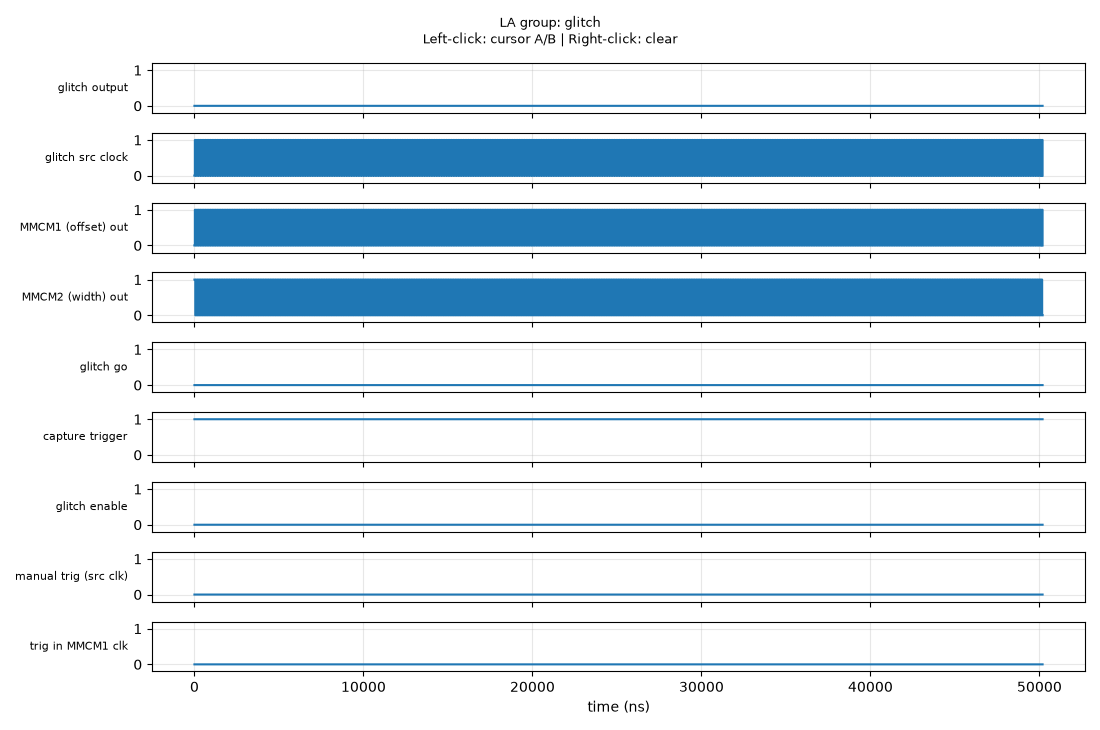

True

In [5]:
import chipwhisperer as cw
import numpy as np
import matplotlib.pyplot as plt
import time


scope = cw.scope()
scope.default_setup()

# ---- glitch setup ----
scope.clock.clkgen_freq = 10e6
scope.glitch.enabled = True
scope.glitch.clk_src = "pll"
# scope.glitch.trigger_src = "manual" # ext_offset is ignored if the trigger is manual 
scope.glitch.output = "enable_only"
#scope.glitch.trigger_src = "ext_single"
scope.glitch.trigger_src = "manual"
scope.glitch.ext_offset = 1
scope.glitch.offset = 10
scope.glitch.width = 10
scope.glitch.repeat = 5

# ---- logic analyzer setup ----
scope.LA.enabled = True
scope.LA.clk_source = "pll"
scope.LA.oversampling_factor = 4
scope.LA.downsample = 1
scope.LA.capture_group = "glitch"
#scope.trigger.triggers = "tio4"       # use a free pin as trigger input
scope.LA.trigger_source = "rising_tio4"   # LA starts on the capture trigger, before the glitch
                                      # Must be one of 'glitch', 'capture', 'glitch_source', 'HS1', '[rising|falling]_userio_d[0-7]', or [rising|falling]_tio[0-3]
scope.LA.capture_depth = 2000         # 100 cycles at 4x oversampling is ~400 samples, 500 is too short

scope.io.tio4 = "gpio_low"    
scope.LA.arm()
scope.arm()
scope.glitch.manual_trigger()

# generate the trigger event yourself by driving tio4 from the Husky
scope.io.tio4 = "gpio_high"           # rising edge on tio4 -> trigger
raw = scope.LA.read_capture_data(check_empty=False)

names = LA_NAMES[scope.LA.capture_group]
n_ch = len(names)
sigs = [scope.LA.extract(raw, i) for i in range(n_ch)]

f_la = scope.LA.sampling_clock_frequency / scope.LA.downsample
t = np.arange(len(sigs[0])) / f_la * 1e9      # ns

calc_la_unit(scope, sigs)
fig = plot_la_interactive(t, sigs, names, unit="ns", title=f"LA group: {scope.LA.capture_group}")

scope.dis()